# Relational Derivation Software and Tools — Worked Walkthrough

**An interactive guide to relational derivation tables, derived-relation networks, matching-to-sample (MTS) procedures, and relational syllogism generation.**

This notebook expands the original examples into a reproducible, progressively structured tutorial. It demonstrates both *what each function produces* and *how changing important arguments changes the task or visualization*.

### Learning objectives

By the end, you should be able to:

1. Construct mutual- and combinatorial-entailment lookup tables for different relational vocabularies.
2. Specify trained baseline relations as indexed stimulus pairs, and derive relations that were not explicitly trained.
3. Compare visualizations of the same relational network and explore derivation depth, training structure, and layout choices.
4. Generate MTS training/test trials while varying repetitions and comparison-set size.
5. Generate relational syllogisms with different task complexity and response formats.
6. Inspect generated outputs and perform basic checks before using them in experiments.

**Scope:** The examples use the high-level `derTables` utilities imported below. The goal-directed, Q-value-weighted derivation algorithm used in the reinforcement-learning simulations is a distinct component and is **not** implemented or demonstrated by the symbolic closure examples here.

**How to use:** Run from the top, section by section. The examples use separate named variables to prevent later demonstrations from overwriting earlier networks. Figures appear inline when your environment supports Matplotlib/Jupyter plotting. No large simulation is run.

## 0. Setup and reproducibility

The notebook expects the **`derTables` package from your project** to be importable in the Python environment running Jupyter. Place the package on your Python path or install it in your environment; its source files are not embedded in this notebook.

The cells below use `numpy`, `pandas`, `matplotlib`, and the project-specific functions. A fixed random seed makes stochastic generation easier to reproduce *within the same software versions and environment*. Exact output contents depend on the implementation of the installed `derTables` version.

In [3]:
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Original project imports, retained from the supplied notebook.
try:
    from derTables.createDerivationTables import createDerivationTables
    from derTables.deriveRelationsFromBaseline import deriveRelationsFromBaseline
    from derTables.GenerateMTS_wip import generateTrials
    from derTables.generateRelationalSyllogisms import generateSyllogism
    from derTables.utils_syllogisms import *
    from derTables.plot_utils import *
    from derTables.utils_tables import *
    from derTables.utils_deictics import *
    from derTables.utils_mts import *
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "The project package `derTables` is not importable. "
        "Start Jupyter from the project environment or add/install derTables "
        "before running this walkthrough."
    ) from exc

SEED = 2026
np.random.seed(SEED)
pd.set_option('display.max_columns', 16)
print('Project tools imported; random seed:', SEED)

Project tools imported; random seed: 2026


### Inspect the installed function interfaces

The project functions may evolve between versions. This cell prints their currently installed signatures, so you can see which options are accepted without relying on assumptions in the tutorial.

In [ ]:
for name, fn in {
    'createDerivationTables': createDerivationTables,
    'deriveRelationsFromBaseline': deriveRelationsFromBaseline,
    'generateTrials': generateTrials,
    'generateSyllogism': generateSyllogism,
}.items():
    try:
        print(f'{name}{inspect.signature(fn)}')
    except (TypeError, ValueError):
        print(f'{name}: signature unavailable')

## 1. Constructing relational derivation tables

`createDerivationTables()` maps a user-selected set of relational labels to integer IDs and produces:

- `relations`: a dictionary mapping labels to IDs;
- `mutual`: the relation resulting from reversing a pair (mutual entailment);
- `combi`: four matrices specifying which relation results from combining two constituent relations in different arrangements.

The lookup tables encode *which relational transformations are permitted*. They do not themselves simulate participant learning or assign reinforcement values.

### 1.1 Full supported relational vocabulary

With no explicit relation list, the function creates its default tables. Turning plotting off is helpful for inspecting data without generating large heatmaps.

In [ ]:
mutual_all, combi_all, relations_all = createDerivationTables(plotTables=False)

print('Number of relation labels:', len(relations_all))
print('Relations (label → index):', relations_all)
print('Combinatorial arrangements:', list(combi_all))
print('Mutual table entries:', len(mutual_all))

### 1.2 Small categorical example: sameness, difference, and opposition

For teaching and publications, a smaller relation set often yields more interpretable figures. Setting `plotTables=True` displays the mutual-entailment and combinatorial-entailment tables.

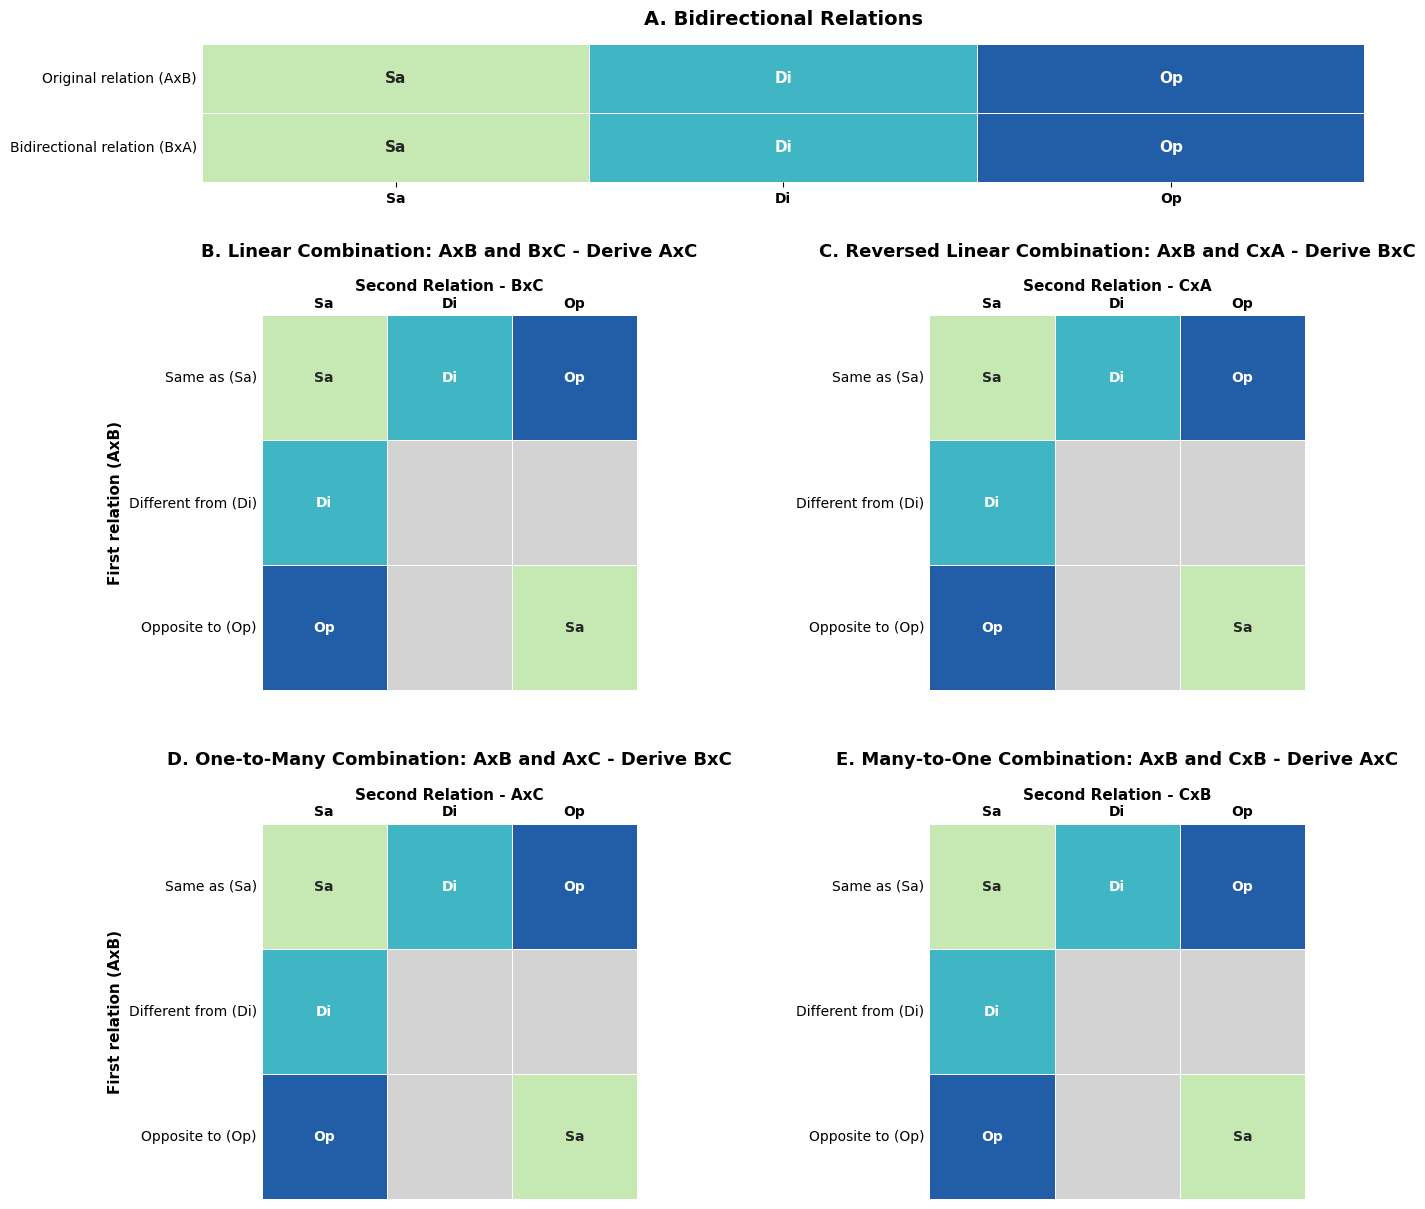

Completed relation vocabulary: ['Same as', 'Different from', 'Opposite to']


In [4]:
basic_relations = ['Same', 'Different', 'Opposite']
mutual_basic, combi_basic, relations_basic = createDerivationTables(
    basic_relations,
    plotTables=True
)
print('Completed relation vocabulary:', list(relations_basic))

### 1.3 Examine a table programmatically

The four combinatorial matrices are indexed by the relation IDs; an entry of `-1` indicates that the table specifies no derivation for that combination. The helper below converts IDs back to readable labels. This is useful for validating tables, checking unusual relations, and exporting lookup tables for methods documentation.

In [5]:
def labelled_composition_table(matrix, relation_ids):
    """Return an ID-based combinatorial matrix as a labelled DataFrame."""
    names_by_id = {int(idx): name for name, idx in relation_ids.items()}
    labels = [names_by_id[i] for i in range(len(names_by_id))]
    raw = np.asarray(matrix)
    if raw.shape != (len(labels), len(labels)):
        raise ValueError('Matrix dimensions do not match the relation vocabulary')
    readable = [
        [names_by_id.get(int(value), 'Not derivable') for value in row]
        for row in raw
    ]
    return pd.DataFrame(readable, index=labels, columns=labels)

example_arrangement = next(iter(combi_basic))
print('Example arrangement:', example_arrangement)
display(labelled_composition_table(combi_basic[example_arrangement], relations_basic))

Example arrangement: Linear


,Same as,Different from,Opposite to
Same as,Same as,Different from,Opposite to
Different from,Different from,Not derivable,Not derivable
Opposite to,Opposite to,Not derivable,Same as


### 1.4 Input completion: a directed comparative relation

Some relations require an inverse to express mutual entailment. For example, a requested *More* relation may trigger inclusion of its inverse. The exact closure of the vocabulary is determined by the installed table-definition code.

In [ ]:
mutual_more, combi_more, relations_more = createDerivationTables(
    ['More'], plotTables=True
)
print('Requested:', ['More'])
print('Available after completion:', list(relations_more))

### 1.5 Input completion: opposition

Composing two opposition relations can yield sameness. This example highlights why the vocabulary used by a derivation table may be larger than the list entered by the user.

In [ ]:
mutual_opp, combi_opp, relations_opp = createDerivationTables(
    ['Opposite'], plotTables=True
)
print('Requested:', ['Opposite'])
print('Available after completion:', list(relations_opp))

### 1.6 A second family: temporal relations

Use the same interface with *Before* and *After* to generate temporal derivation tables. The table structure and plotting logic remain unchanged, showing how one program supports different contextual relations.

In [ ]:
mutual_time, combi_time, relations_time = createDerivationTables(
    ['Before', 'After'], plotTables=True
)
print('Temporal relations:', list(relations_time))

### 1.7 Quick reference: table-generation parameters

| Parameter | Example | Purpose |
|---|---|---|
| First argument | `['Same', 'Different', 'Opposite']` | Select the initial relational vocabulary |
| First argument omitted | *(none)* | Use the library's default supported relations |
| `plotTables` | `False` | Inspect data without making figures |
| `plotTables` | `True` | Visualize mutual and four combinatorial tables |

**Interpretation:** A table entry licenses a possible symbolic derivation. It does not establish that a human participant would necessarily derive that relation in a behavioral experiment.

## 2. Deriving relations from a trained network

`deriveRelationsFromBaseline()` takes a dictionary of baseline relations and a stimulus-label list, then computes derived relations implied by the relation tables. The inputs use **integer indices into `sLabs`**, not the stimulus labels themselves. For example, `(0, 1)` refers to the first and second stimuli.

The returned objects are `relTab` (a relational table/representation) and `derived` (derived relations). The precise representation depends on the version of the installed project code.

### 2.1 A mixed relational network (Steele & Hayes-style example)

This reproduces the network already included in the original notebook. `N1` and `N2` are included in the label list but not connected by these baseline training relations.

In [ ]:
stimuli_mixed = ['A', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3', 'N1', 'N2']
baseline_mixed = {
    'Same as': [(0, 1), (0, 4)],
    'Different from': [(0, 3), (0, 6)],
    'Opposite to': [(0, 2), (0, 5)],
}

for relation, pairs in baseline_mixed.items():
    for left, right in pairs:
        print(f'{stimuli_mixed[left]} — {relation} — {stimuli_mixed[right]}')

relTab_mixed, derived_mixed = deriveRelationsFromBaseline(
    baseline_mixed,
    stimuli_mixed,
    illustrate='print'
)

### 2.2 Visualize the **same** network in three ways

The `illustrate` option changes *how* the results are displayed, not the baseline network being derived. Use `print` when auditing individual consequences, `heatmap` for dense relational patterns, and `graph` to communicate network structure.

In [ ]:
relTab_mixed_heat, derived_mixed_heat = deriveRelationsFromBaseline(
    baseline_mixed, stimuli_mixed, illustrate='heatmap'
)

In [ ]:
relTab_mixed_graph, derived_mixed_graph = deriveRelationsFromBaseline(
    baseline_mixed, stimuli_mixed, illustrate='graph'
)

### 2.3 A seven-item transitive-inference chain

This example trains only adjacent *More than* relations: A > B > C > D > E > F > G. Nonadjacent consequences such as A > G require composition across multiple baseline links. `max_depth=None` requests unrestricted depth where supported by the function; the number of distinct stimuli still bounds simple paths in a finite network.

This use case is well suited to studying **symbolic/nodal distance** and to inspecting whether an algorithm derives long-range relations.

In [ ]:
stimuli_chain = list('ABCDEFG')
baseline_chain = {
    'More than': [(i, i + 1) for i in range(len(stimuli_chain) - 1)]
}

relTab_chain, derived_chain = deriveRelationsFromBaseline(
    baseline_chain,
    stimuli_chain,
    illustrate='graph',
    max_depth=None
)

### 2.4 Compare shorter versus longer derivation depth

`max_depth` limits how far the algorithm can compose relations. It is particularly useful for demonstrations of limited derivation or for controlling computation. We rerun the same chain with a smaller depth limit and **inspect the returned outputs**, because the exact meaning and treatment of depth depend on the installed function version.

In [ ]:
relTab_chain_shallow, derived_chain_shallow = deriveRelationsFromBaseline(
    baseline_chain,
    stimuli_chain,
    illustrate='print',
    max_depth=2
)

print('Return type (shallow):', type(derived_chain_shallow).__name__)
print('Return type (unrestricted):', type(derived_chain).__name__)
if isinstance(derived_chain_shallow, dict) and isinstance(derived_chain, dict):
    print('Top-level keys (shallow):', list(derived_chain_shallow))
    print('Top-level keys (unrestricted):', list(derived_chain))

### 2.5 Training structure: Linear, one-to-many, and many-to-one

The same equivalence-class membership can be trained with different arrangements of baseline relations. The following networks all involve two three-member classes, but differ in which stimulus serves as sample or common node.

- **Linear:** A→B→C within each class.
- **One-to-many (OTM):** A→B and A→C.
- **Many-to-one (MTO):** A→C and B→C.

These are examples of **symbolic baseline specifications**, not simulations of the Q-learning model. They are useful for showing how graph structure affects which relations must be derived.

In [ ]:
stimuli_classes = ['A1', 'B1', 'C1', 'A2', 'B2', 'C2']
structure_baselines = {
    'Linear': {'Same as': [(0, 1), (1, 2), (3, 4), (4, 5)]},
    'OTM':    {'Same as': [(0, 1), (0, 2), (3, 4), (3, 5)]},
    'MTO':    {'Same as': [(0, 2), (1, 2), (3, 5), (4, 5)]},
}

structure_derivations = {}
for structure, baseline in structure_baselines.items():
    print(f'\n=== {structure} ===')
    rel_tab, derived = deriveRelationsFromBaseline(
        baseline, stimuli_classes, illustrate='print'
    )
    structure_derivations[structure] = {'relTab': rel_tab, 'derived': derived}

### 2.6 Visualize a selected network with the dedicated graph utility

The existing project also provides `plotRelNetworkGraph`, which gives you direct control over displayed relation types and layout. This cell uses the arguments from the project's graph-plotting API.

Common settings include `layout='spring'`, `'circle'`, `'kamada_kawai'`, or `'grid'`; `plotRels` can be restricted to trained (`baseline`), mutual, or combinatorial relations. This is helpful when a fully annotated graph becomes crowded.

In [ ]:
if 'plotRelNetworkGraph' not in globals():
    print('plotRelNetworkGraph is not exported by this version of derTables.plot_utils.')
else:
    plotRelNetworkGraph(
        structure_baselines['Linear'],
        derived=structure_derivations['Linear']['derived'],
        sLabs=stimuli_classes,
        plotRels=['baseline', 'mutual', 'combi'],
        plotTitle='Two three-member classes: Linear training',
        layout='spring'
    )

### 2.7 Alternative graph layout and only baseline relations

Use a circle arrangement and turn off derived relations to display the training contingencies by themselves. Exact accepted `plotRels` values and layouts can be checked against `inspect.signature(plotRelNetworkGraph)` and the project's visualizer documentation.

In [ ]:
if 'plotRelNetworkGraph' in globals():
    plotRelNetworkGraph(
        structure_baselines['OTM'],
        derived=structure_derivations['OTM']['derived'],
        sLabs=stimuli_classes,
        plotRels=['baseline'],
        plotTitle='One-to-many baseline network',
        layout='circle'
    )

### 2.8 Validate the baseline definition before deriving

A frequent error is an out-of-range stimulus index. This small check verifies that every pair references known stimuli. It is particularly useful when networks are constructed programmatically.

In [ ]:
def validate_baseline(baseline, stimulus_labels):
    n = len(stimulus_labels)
    problems = []
    for relation, pairs in baseline.items():
        for pair in pairs:
            if len(pair) != 2 or any(not isinstance(i, (int, np.integer)) for i in pair):
                problems.append((relation, pair, 'expected a pair of integer indices'))
            elif any(i < 0 or i >= n for i in pair):
                problems.append((relation, pair, f'indices must fall within 0..{n-1}'))
    return problems

for name, baseline in structure_baselines.items():
    issues = validate_baseline(baseline, stimuli_classes)
    print(f'{name}:', 'OK' if not issues else issues)

## 3. Generating matching-to-sample (MTS) tasks

`generateTrials()` builds trial-level training and testing schedules from a baseline network. The original notebook uses the **Manual** preset, which lets you define the baseline relation dictionary and stimulus labels directly.

Useful parameters:

| Argument | Purpose | Example |
|---|---|---|
| `baseline` | Trained relations as indexed pairs | `{'Same as': [(0,1), ...]}` |
| `n_baseline` | Repetitions of baseline training relations | `2` or `5` |
| `preset` | Protocol selection; `Manual` uses supplied relations | `'Manual'` |
| `n_test` | Repetitions of derived/test relations | `1` or `3` |
| `n_comp` | Number of presented response alternatives | `3` or `4` |
| `printTrials` | Verbose display of generated trials | `True` / `False` |
| `sLabs` | Display names for stimulus indices | `['A1','B1', ...]` |

**Caution:** `n_comp` includes the correct comparison, so a three-comparison trial has two distractors. Trial counts and labels can vary depending on which derived relations are included by the installed generator.

### 3.1 Small two-class example (three comparison options)

Start with two three-member equivalence classes in a Linear arrangement. Keep verbose printing off and inspect the generated DataFrame directly.

In [ ]:
mts_stimuli = ['A1', 'B1', 'C1', 'A2', 'B2', 'C2']
mts_baseline = {
    'Same as': [(0, 1), (1, 2), (3, 4), (4, 5)]
}

np.random.seed(SEED)
mts_small = generateTrials(
    mts_baseline,
    n_baseline=2,
    preset='Manual',
    n_test=1,
    n_comp=3,
    printTrials=False,
    sLabs=mts_stimuli
)
print('Shape:', mts_small.shape)
display(mts_small.head(8))

### 3.2 Inspect available trial types and example rows

Do not assume a particular schema without checking the generated table. The following helper works with the returned DataFrame and prints common trial descriptors only when available.

In [ ]:
def inspect_mts_trials(df, n_examples=3, seed=SEED):
    print('Rows:', len(df))
    print('Columns:', list(df.columns))
    if 'type' in df.columns:
        print('Trial types:')
        print(df['type'].value_counts(dropna=False).to_string())
    n = min(n_examples, len(df))
    if n:
        rng = np.random.default_rng(seed)
        indices = rng.choice(len(df), size=n, replace=False)
        for k, idx in enumerate(indices, start=1):
            print(f'\nExample {k} (row {idx}):')
            print(df.iloc[int(idx)].to_string())

inspect_mts_trials(mts_small)

### 3.3 More training repetitions and four comparison options

Hold the baseline network constant and increase both the number of baseline repetitions and the number of comparisons. This changes how much training the generator includes and how many response options each trial displays.

In [ ]:
np.random.seed(SEED)
mts_four_options = generateTrials(
    mts_baseline,
    n_baseline=5,
    preset='Manual',
    n_test=2,
    n_comp=4,
    printTrials=False,
    sLabs=mts_stimuli
)

print('Three options:', len(mts_small), 'total rows')
print('Four options / more repetitions:', len(mts_four_options), 'total rows')
display(mts_four_options.head(5))

### 3.4 Compare training structures with the same trial-generation settings

A helpful use case is producing corresponding MTS tasks for Linear, OTM, and MTO training while leaving `n_baseline`, `n_test`, and `n_comp` fixed. These are *generated schedules*, not outcome data. Differences in the resulting number or type of test trials should be inspected rather than assumed.

In [ ]:
mts_by_structure = {}
summary_rows = []

for name, baseline in structure_baselines.items():
    np.random.seed(SEED)
    trials = generateTrials(
        baseline,
        n_baseline=2,
        preset='Manual',
        n_test=1,
        n_comp=3,
        printTrials=False,
        sLabs=stimuli_classes
    )
    mts_by_structure[name] = trials
    row = {'Structure': name, 'Total rows': len(trials)}
    if 'type' in trials.columns:
        row.update({f'Type: {key}': value for key, value in trials['type'].value_counts().items()})
    summary_rows.append(row)

display(pd.DataFrame(summary_rows).fillna(0))

### 3.5 A larger OTM network and verbose trial printing

This revisits the original notebook's four-member class example. To keep the output readable, verbose printing is enabled with only one repetition of each training/test relation. The stimulus list can include additional labels that are not connected by the trained baseline; those labels should not be confused with explicitly trained class members.

In [ ]:
mts_large_labels = [
    'A1', 'A2', 'A3', 'A4',
    'B1', 'B2', 'B3', 'B4',
    'C1', 'C2', 'C3', 'C4',
    'D1', 'D2', 'D3', 'D4'
]
mts_large_baseline = {
    'Same as': [(0, 1), (0, 2), (0, 3),
                (4, 5), (4, 6), (4, 7)]
}

np.random.seed(SEED)
mts_large = generateTrials(
    mts_large_baseline,
    n_baseline=1,
    preset='Manual',
    n_test=1,
    n_comp=4,
    printTrials=True,
    sLabs=mts_large_labels
)
print('Generated rows:', len(mts_large))

### 3.6 Save a generated trial schedule

Exporting as CSV is convenient for inspection or subsequent task programming. For columns containing Python lists (e.g., multiple comparison labels), CSV preserves a textual representation; **pickle or Parquet may better retain Python object types** if you need to load the schedule back without parsing.

In [ ]:
# Uncomment the next two lines to save an example in your working directory.
# output_path = Path('mts_example_schedule.csv')
# mts_small.to_csv(output_path, index=False)

print('Example columns available for export:', list(mts_small.columns))

## 4. Generating relational syllogisms

`generateSyllogism()` constructs reasoning problems from relational premises. Unlike an MTS trial, a syllogism presents **multiple premises** and asks the participant to evaluate possible conclusions or statements.

The original notebook demonstrates a typical n-term reasoning task using comparative dimensions (faster/slower and stronger/weaker), named relata, and both incorrect and mutually entailed conclusions.

Key options include:

- `relations`: relational vocabulary used in the problems;
- `premises_types`: problem types selected for different numbers of premises;
- `n_rep`: repetition count;
- `relata`: content used for stimulus names (the supplied example uses `'names'`);
- `protocol`: structure used to generate the premises;
- `n_opt`: number of response options;
- `printTrials`: print examples while generating.

The specific keys accepted by `premises_types` and additional `protocol` values are defined by your installed package. The examples below use combinations already present in the original notebook.

### 4.1 Four relational terms, two to four premises

This is the original example, now with a short inspection of the returned trials.

In [1]:
syllogism_relations = ['faster', 'slower', 'stronger', 'weaker']
syllogism_types = {
    '2': ['Incorrect', 'MutualCE'],
    '3': ['Incorrect', 'MutualCE'],
    '4': ['Incorrect', 'MutualCE'],
}

np.random.seed(SEED)
syllogisms_full = generateSyllogism(
    relations=syllogism_relations,
    premises_types=syllogism_types,
    n_rep=4,
    relata='names',
    protocol='Linear',
    n_opt=3,
    printTrials=False
)
print('Generated trials:', len(syllogisms_full))
display(syllogisms_full.head(5))

NameError: name 'np' is not defined

### 4.2 Shorter problems with fewer response options

To create a briefer teaching or pilot task, restrict the problem specification to two premises, use fewer repetitions, and reduce the number of answer options. Before running a real experiment, inspect the correct-answer field and whether multiple responses can be valid.

In [ ]:
np.random.seed(SEED)
syllogisms_short = generateSyllogism(
    relations=syllogism_relations,
    premises_types={'2': ['Incorrect', 'MutualCE']},
    n_rep=1,
    relata='names',
    protocol='Linear',
    n_opt=2,
    printTrials=False
)
print('Brief task rows:', len(syllogisms_short))
display(syllogisms_short.head(3))

### 4.3 Preview three randomly selected syllogisms

The preview displays available output fields without assuming the exact schema of every version of the generator. The same utility can be used to check task content before exporting trials to an experimental platform.

In [ ]:
def preview_syllogisms(df, n=3, seed=SEED):
    if df.empty:
        print('No trials were generated.')
        return
    sample = df.sample(n=min(n, len(df)), random_state=seed)
    for j, (_, trial) in enumerate(sample.iterrows(), start=1):
        print(f'\n--- Syllogism {j} ---')
        for name in ('Type', 'Premises', 'Prompt', 'printCorrect'):
            if name in trial.index:
                value = trial[name]
                if isinstance(value, (list, tuple)):
                    value = ' '.join(map(str, value))
                print(f'{name}: {value}')
        remaining = [name for name in ('Correct', 'Options', 'Responses') if name in trial.index]
        for name in remaining:
            print(f'{name}: {trial[name]}')

preview_syllogisms(syllogisms_full)

### 4.4 Compare complexity settings

For a transparent parameter check, this final syllogism example prints the number of generated rows and any available type counts for the shorter and fuller task variants. More rows do not by themselves establish higher psychological difficulty; difficulty also depends on the relational rules and how many relational compositions the task requires.

In [ ]:
for label, trials in [('Brief (2 premises)', syllogisms_short),
                      ('Full (2–4 premises)', syllogisms_full)]:
    print(f'\n{label}: {len(trials)} rows')
    if 'Type' in trials.columns:
        print(trials['Type'].value_counts().to_string())

# Optional export:
# syllogisms_full.to_csv('relational_syllogisms.csv', index=False)

## 5. Choosing an appropriate workflow

| Research or development goal | Recommended tool | Useful parameter changes |
|---|---|---|
| Define which relational transformations are permitted | `createDerivationTables` | Relation vocabulary; `plotTables` |
| Inspect a symbolic network's implied relations | `deriveRelationsFromBaseline` | Baseline pairs; `illustrate`; `max_depth` |
| Present a relational network visually | `plotRelNetworkGraph` or `illustrate='graph'` | Layout; displayed relation categories; labels |
| Generate a basic equivalence-class MTS task | `generateTrials` | Training structure; `n_baseline`; `n_test`; `n_comp` |
| Construct longer chains for transitive inference | `deriveRelationsFromBaseline` | Comparison network; chain length; depth |
| Generate multi-premise verbal reasoning problems | `generateSyllogism` | Relation terms; premise types; repetitions; response options |

### Practical checks before using generated material in a study

1. **Check relation indices:** all baseline pairs should refer to valid entries in the supplied stimulus list.
2. **Check trial types and keys:** inspect the returned DataFrame rather than assuming the same column names across software versions.
3. **Check comparison lists:** make sure each trial contains the intended number of response options and one appropriate keyed response.
4. **Check derived outcomes:** review a small network manually, especially when using newly added relational vocabularies.
5. **Check reproducibility:** save random seeds, package versions, training definitions, and exported trial files.
6. **Distinguish symbolic derivation from learning:** symbolic closure computes consequences from specified relations; reinforcement-learning simulations additionally model acquisition, response values, and stochastic selection.

### Possible extensions

Further examples could include contextual control with conditional discriminations, network layouts with user-defined node positions, deictic-relational syllogisms, or direct comparisons with the goal-directed Q-value derivation engine. Such demonstrations require checking the relevant function interfaces and, for reinforcement learning, the corresponding model implementation.

## 6. Environment and reproducibility record

Run this cell when sharing a notebook or reporting an experiment. It records the Python/library versions and working directory without modifying generated stimuli or trials.

In [ ]:
import sys
from importlib import metadata

print('Python:', sys.version.split()[0])
print('Working directory:', Path.cwd())
for pkg in ('numpy', 'pandas', 'matplotlib', 'seaborn', 'derTables'):
    try:
        print(f'{pkg}: {metadata.version(pkg)}')
    except metadata.PackageNotFoundError:
        print(f'{pkg}: package version not available via metadata')

print('Random seed used in examples:', SEED)